# Partycjonowanie fizyczne i benchmark A/B — GIOŚ

Logika: `scripts/partition_benchmark.py`. Notebook wywołuje funkcje i prezentuje wyniki. Uruchom po `04_silver.ipynb`.

Zamiast VendorID filtrujemy po `wskaznik`; zamiast dystansu i napiwku liczymy średnie stężenie według godziny UTC. W projekcie nie ma danych taksówkowych. Do agregacji wybieramy wyłącznie pomiary `1g`. W kontroli bez filtra liczymy oddzielne średnie dla każdego wskaźnika, bez mieszania jednostek.

A: płaski Parquet. B: partycje Hive `wskaznik=.../`. Oba warianty: Snappy i taki sam limit wielkości grup wierszy. Test jest wykonywany na całym zbiorze silver, a nie próbce.

To pomiar całego zapytania przy rozgrzanym cache systemu, a nie pomiar fizycznego transferu dysku. Cache systemu nie jest czyszczony.


## 1. Skrypt i ustawienia

Dodaj `matplotlib>=3.9,<4` do requirements.txt i zainstaluj zależności w środowisku projektu.

Domyślne `write_statistics=False` wyłącza statystyki grup w obu zapisach, aby odseparować pruning plików od pomijania grup na podstawie min/max. To ustawienie eksperymentalne, nie zalecenie produkcyjne. Osobny test produkcyjny można wykonać przez utworzenie nowego kontekstu z `write_statistics=True`.


In [1]:
from pathlib import Path
import runpy
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
SCRIPT = ROOT / "scripts" / "partition_benchmark.py"
if not SCRIPT.is_file():
    raise FileNotFoundError(f"Umieść skrypt w: {SCRIPT}")
benchmark = runpy.run_path(str(SCRIPT))
ctx = benchmark["create_context"](
    root=ROOT, repeats=20, warmups=3, write_statistics=False
)
print("Wejście:", ctx["source"])
print("Dane A/B:", ctx["data"])
print("Raport:", ctx["report"])


Wejście: D:\Projekty\gios-bigdata\data\silver\pomiary_2024.parquet
Dane A/B: D:\Projekty\gios-bigdata\data\benchmark\20261114T220012_582298Z
Raport: D:\Projekty\gios-bigdata\reports\partition_benchmark\20261114T220012_582298Z


## 2. Zapis i struktura podkatalogów

Silver nie jest nadpisywane. Każdy nowy kontekst tworzy osobne katalogi. Ponowne wykonanie samego zapisu zgłosi błąd zamiast nadpisać pliki; aby powtórzyć cały etap, utwórz nowy kontekst.


In [2]:
storage = benchmark["write_variants"](ctx)
print(storage["tree"])
display(storage["files"])
display(storage["storage"])


data\benchmark\20261114T220012_582298Z\partitioned/
  wskaznik=123trimetylobenzen/
    part-0.parquet (1,263 wierszy, 24,467 B)
  wskaznik=124trimetylobenzen/
    part-0.parquet (3,809 wierszy, 71,363 B)
  wskaznik=135trimetylobenzen/
    part-0.parquet (4,095 wierszy, 77,067 B)
  wskaznik=13butadien/
    part-0.parquet (898 wierszy, 17,835 B)
  wskaznik=1buten/
    part-0.parquet (1,528 wierszy, 28,806 B)
  wskaznik=1penten/
    part-0.parquet (496 wierszy, 10,886 B)
  wskaznik=2penten/
    part-0.parquet (291 wierszy, 7,280 B)
  wskaznik=acetylen/
    part-0.parquet (2,592 wierszy, 48,180 B)
  wskaznik=As%28PM10%29/
    part-0.parquet (20,131 wierszy, 387,007 B)
  wskaznik=BaA%28PM10%29/
    part-0.parquet (6,737 wierszy, 139,503 B)
  wskaznik=BaP%28PM10%29/
    part-0.parquet (60,582 wierszy, 905,707 B)
  wskaznik=BbF%28PM10%29/
    part-0.parquet (6,736 wierszy, 140,503 B)
  wskaznik=BjF%28PM10%29/
    part-0.parquet (6,736 wierszy, 139,838 B)
  wskaznik=BkF%28PM10%29/
    part-0.p

partition,file,rows,bytes,row_groups
str,str,i64,i64,i64
"""wskaznik=123trimetylobenzen""","""part-0.parquet""",1263,24467,1
"""wskaznik=124trimetylobenzen""","""part-0.parquet""",3809,71363,1
"""wskaznik=135trimetylobenzen""","""part-0.parquet""",4095,77067,2
"""wskaznik=13butadien""","""part-0.parquet""",898,17835,1
"""wskaznik=1buten""","""part-0.parquet""",1528,28806,1
…,…,…,…,…
"""wskaznik=propen""","""part-0.parquet""",2004,36894,1
"""wskaznik=SO2""","""part-0.parquet""",665875,12088122,101
"""wskaznik=SO42_%28PM2.5%29""","""part-0.parquet""",1789,38890,5


variant,files,rows,bytes
str,i64,i64,i64
"""A""",1,8472637,54847836
"""B""",63,8472637,154505753


## 3. Kontrola zgodności

Kontrola schematu, liczebności i agregatów według wskaźnika, czasu uśredniania i godziny. Dla zmiennoprzecinkowych sum i średnich stosowana jest tolerancja. Wyniki każdego scenariusza A/B są dodatkowo porównywane.


In [3]:
validation = benchmark["verify_data"](ctx)
print(validation)


{'status': 'OK', 'source_rows': 8472637, 'A_rows': 8472637, 'B_rows': 8472637, 'checked_groups': 961}


## 4. Różne przykłady i plany zapytań

Dobór automatyczny: do czterech wskaźników o różnych liczebnościach, w tym PM2.5, jeśli występuje, oraz kontrola bez filtra klucza partycji.
Możesz podać np. `indicators=["PM2.5", "PM10", "NO2", "O3"]` zamiast None. Skrypt sprawdzi dostępność pomiarów godzinowych.


In [4]:
scenarios = benchmark["prepare_scenarios"](ctx, indicators=None)
display(scenarios)
first_id = ctx["scenarios"][0]["id"]
for variant in ("A", "B"):
    print(f"\nWariant {variant}:")
    print(ctx["queries"][first_id, variant])
    path = ctx["report"] / f"plan_{first_id}_{variant}.txt"
    print(path.read_text(encoding="utf-8"))


id,scenario,indicator,hourly_rows,hourly_share_pct
str,str,str,i64,f64
"""q01""","""wskaznik=PM10""","""PM10""",1518694,18.516052
"""q02""","""wskaznik=135trimetylobenzen""","""135trimetylobenzen""",4095,0.049927
"""q03""","""wskaznik=ibutan""","""ibutan""",3025,0.036881
"""q04""","""wskaznik=PM2.5""","""PM2.5""",816760,9.95801
"""control""","""kontrola_bez_filtra""",null,8202040,100.0



Wariant A:
SELECT wskaznik,hour(data_czas_utc) AS godzina_utc,
        avg(wartosc) AS srednie_stezenie,count(*) AS liczba_pomiarow
        FROM read_parquet('D:/Projekty/gios-bigdata/data/benchmark/20261114T220012_582298Z/flat.parquet', hive_partitioning=false) WHERE czas_usredniania='1g'  AND wskaznik='PM10'
        GROUP BY 1,2 ORDER BY 1,2
╭─ Summary ──────────╮
│ Total Time: 0.198s │
│ Data Read: 43.7 MB │
╰────────────────────╯
╭─ Order By ───────────────────────────────────────────────────────────────────╮
│ Order By: wskaznik ASC, godzina_utc ASC                                      │
│ 24 rows                                                                  0µs │
╰───────────────────────────────────────┬──────────────────────────────────────╯
╭─ Hash Group By ───────────────────────┴──────────────────────────────────────╮
│ Groups: #0, #1                                                               │
│ Aggregates: avg(#2), count_star()                                        

## 5. Wielokrotne pomiary

Trzy rozgrzewki każdego zapytania i 20 powtórzeń na scenariusz i wariant. Kolejność scenariuszy i A/B jest losowana w każdej rundzie. Stała liczba wątków i to samo połączenie DuckDB. Mierzone jest `execute` + `fetchall`. Zapis, walidacja, plany i wykresy są poza czasem pomiaru.


In [5]:
timings = benchmark["run_benchmark"](ctx)
print("Liczba pomiarów:", timings.height)
with pl.Config(tbl_rows=timings.height):
    display(timings)


Liczba pomiarów: 200


id,scenario,iteration,variant,position_in_pair,time_ms,result_rows
str,str,i64,str,i64,f64,i64
"""q04""","""wskaznik=PM2.5""",1,"""B""",1,166.575,24
"""q04""","""wskaznik=PM2.5""",1,"""A""",2,158.4122,24
"""q02""","""wskaznik=135trimetylobenzen""",1,"""B""",1,97.2762,24
"""q02""","""wskaznik=135trimetylobenzen""",1,"""A""",2,53.9854,24
"""q03""","""wskaznik=ibutan""",1,"""B""",1,63.9384,24
"""q03""","""wskaznik=ibutan""",1,"""A""",2,69.096,24
"""control""","""kontrola_bez_filtra""",1,"""B""",1,810.5886,936
"""control""","""kontrola_bez_filtra""",1,"""A""",2,388.8574,936
"""q01""","""wskaznik=PM10""",1,"""B""",1,214.0056,24


## 6. Zestawienie

Zysk = `(średnia_A - średnia_B) / średnia_A × 100%`. Ujemny wynik oznacza wolniejsze B. A/B = 2 oznacza dwukrotnie krótszy czas B. SD to odchylenie standardowe, nie przedział ufności.
Pełna tabela w summary.csv obejmuje także minimum i maksimum.


In [6]:
summary = benchmark["summarize"](ctx, timings)
display(Markdown((ctx["report"] / "summary.md").read_text(encoding="utf-8")))
with pl.Config(tbl_cols=summary.width):
    display(summary)


| scenario | repeats | A_mean_ms | B_mean_ms | A_median_ms | B_median_ms | A_std_ms | B_std_ms | time_saved_percent | speedup_A_over_B |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| wskaznik=PM10 | 20 | 183.052 | 201.025 | 180.269 | 190.222 | 27.734 | 39.182 | -9.819 | 0.911 |
| wskaznik=135trimetylobenzen | 20 | 73.992 | 69.343 | 68.218 | 65.148 | 27.331 | 20.595 | 6.282 | 1.067 |
| wskaznik=ibutan | 20 | 71.529 | 70.243 | 64.971 | 62.422 | 17.103 | 22.739 | 1.797 | 1.018 |
| wskaznik=PM2.5 | 20 | 151.970 | 160.337 | 153.083 | 162.348 | 19.908 | 33.692 | -5.506 | 0.948 |
| kontrola_bez_filtra | 20 | 338.140 | 893.449 | 326.295 | 895.697 | 41.271 | 61.037 | -164.225 | 0.378 |

id,scenario,repeats,A_mean_ms,A_median_ms,A_std_ms,A_min_ms,A_max_ms,B_mean_ms,B_median_ms,B_std_ms,B_min_ms,B_max_ms,time_saved_percent,speedup_A_over_B
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""q01""","""wskaznik=PM10""",20,183.052105,180.26895,27.734462,134.5409,250.2016,201.025325,190.2216,39.181761,160.8528,299.5524,-9.818636,0.910592
"""q02""","""wskaznik=135trimetylobenzen""",20,73.991545,68.21775,27.331092,50.5716,172.2085,69.34305,65.14845,20.595268,39.8921,125.9575,6.282468,1.067036
"""q03""","""wskaznik=ibutan""",20,71.5288,64.97065,17.103291,52.5555,98.8706,70.24321,62.42235,22.739337,36.7649,118.5541,1.797304,1.018302
"""q04""","""wskaznik=PM2.5""",20,151.96984,153.0829,19.908083,116.211,188.4709,160.337405,162.3482,33.691837,108.5945,235.7815,-5.506069,0.947813
"""control""","""kontrola_bez_filtra""",20,338.139745,326.29455,41.271109,288.5058,451.1283,893.44895,895.6968,61.037347,781.2261,990.6476,-164.224766,0.378466


## 7. Wykresy

Średnie czasy z odchyleniem standardowym, procentowy zysk oraz przebieg wszystkich powtórzeń. Skrypt zapisuje PNG; notebook wyświetla figury.


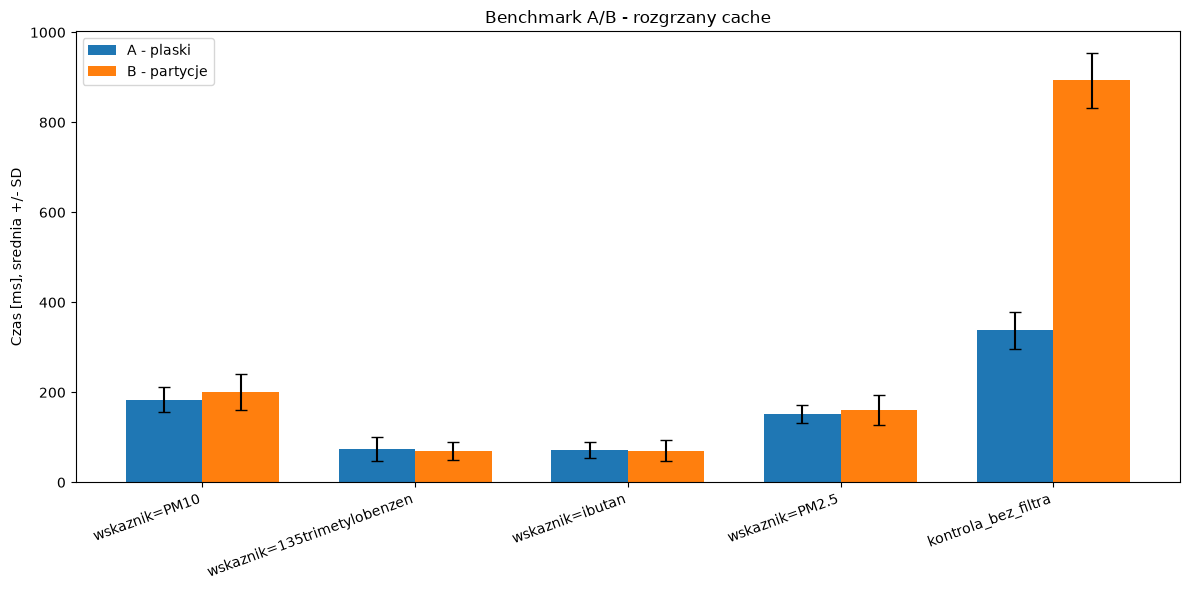

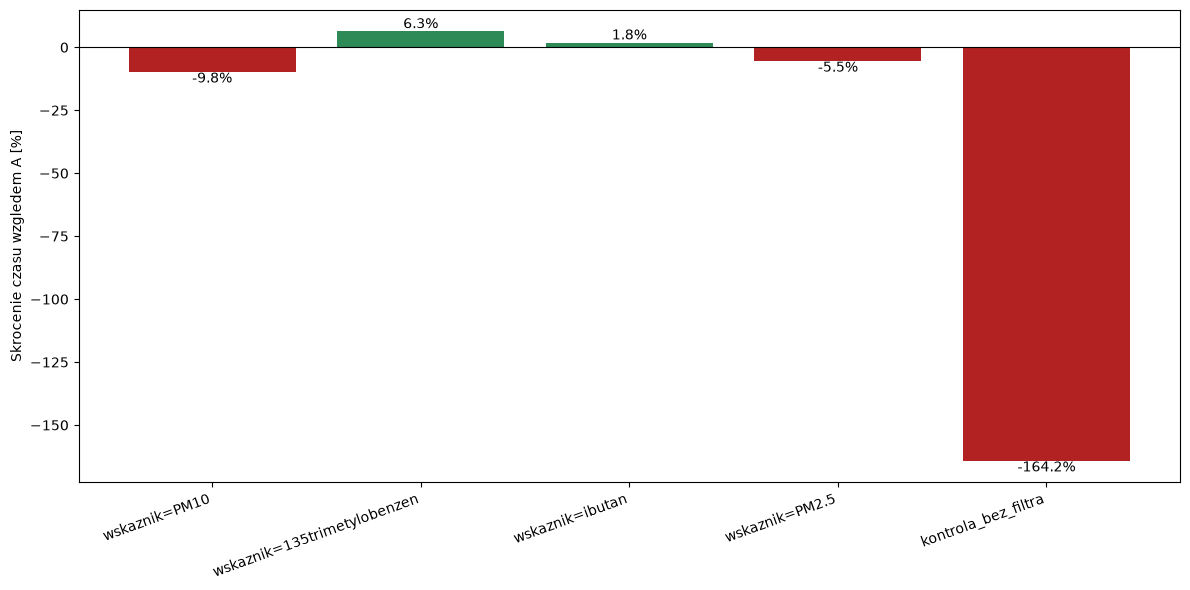

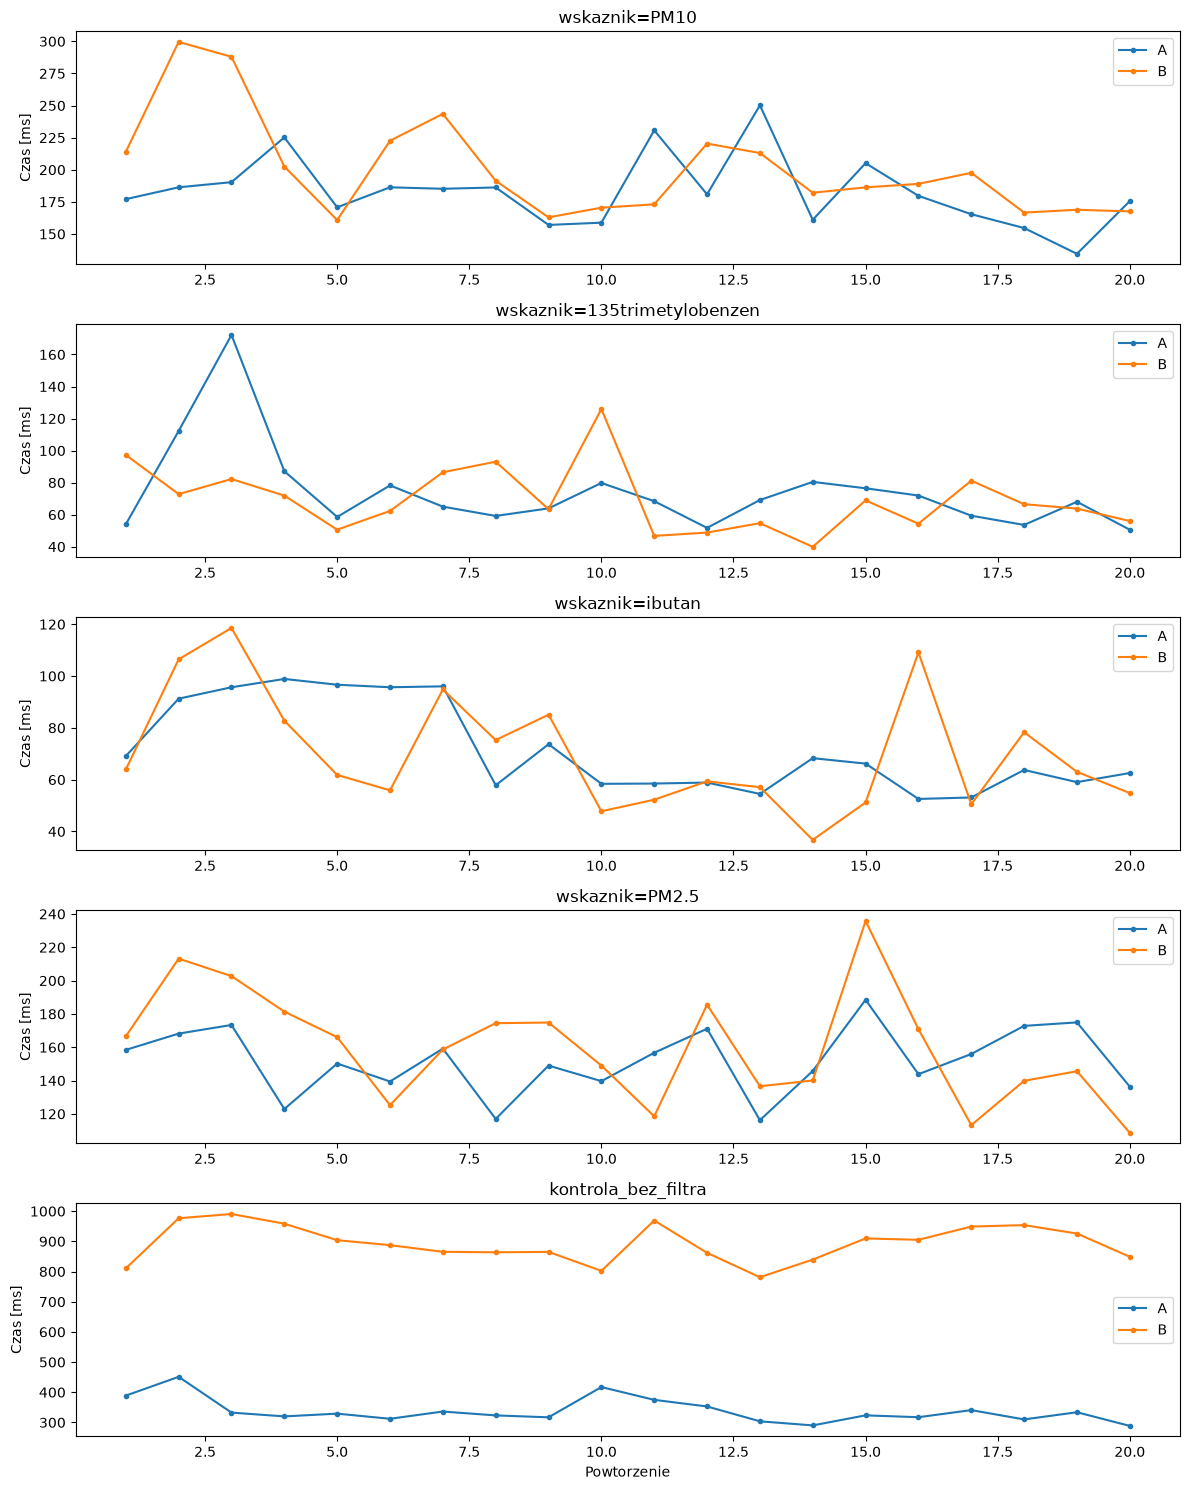

In [7]:
figures = benchmark["make_plots"](ctx, timings, summary)
for figure in figures:
    display(figure)
    plt.close(figure)


## 8. Wnioski

### Poprawność danych i zakres testu

Oba warianty zawierają po 8 472 637 wierszy. Kontrola schematów, liczebności i agregatów zakończyła się wynikiem `OK`; sprawdzono 961 grup. Wyniki zapytań A/B również były porównywane. Zmiana organizacji zapisu nie zmieniła wyników analiz w zakresie wykonanych kontroli.

Zastosowano 3 rozgrzewki i po 20 powtórzeń dla każdego wariantu w pięciu scenariuszach, łącznie 200 pomiarów. Zapytania obejmowały wyłącznie pomiary godzinowe. Zbiór tych pomiarów liczył 8 202 040 wierszy; zapis A/B obejmował jednak cały zbiór silver, również dane o innym czasie uśredniania.

### Porównanie czasów

| Scenariusz | Średnia A [ms] | Średnia B [ms] | Mediana A [ms] | Mediana B [ms] | Zysk czasu B względem A |
|---|---:|---:|---:|---:|---:|
| PM10 | 183,052 | 201,025 | 180,269 | 190,222 | −9,819% |
| 135trimetylobenzen | 73,992 | 69,343 | 68,218 | 65,148 | +6,282% |
| ibutan | 71,529 | 70,243 | 64,971 | 62,422 | +1,797% |
| PM2.5 | 151,970 | 160,337 | 153,083 | 162,348 | −5,506% |
| Kontrola bez filtra wskaźnika | 338,140 | 893,449 | 326,295 | 895,697 | −164,225% |

Największe skrócenie średniego czasu uzyskano dla 135trimetylobenzenu: około 4,649 ms, czyli 6,282%. Dla ibutanu korzyść była niewielka: około 1,286 ms, czyli 1,797%. Dla PM10 wariant partycjonowany był wolniejszy o około 17,973 ms (9,819%), a dla PM2.5 o około 8,367 ms (5,506%). Mediany potwierdzają kierunek różnic we wszystkich pięciu scenariuszach.

Rozrzut jest jednak znaczny w porównaniu z niewielkimi różnicami dla zapytań filtrowanych. Przykładowo dla 135trimetylobenzenu odchylenia standardowe wyniosły 27,331 ms w A i 20,595 ms w B, przy różnicy średnich zaledwie 4,649 ms. Dla ibutanu było to odpowiednio 17,103 i 22,739 ms, przy różnicy 1,286 ms. Są to opisowe wyniki tej serii; bez analizy niepewności nie dowodzą trwałej ani statystycznie istotnej przewagi B.

### Zależność od wielkości wybranej części danych

PM10 obejmował 1 518 694 pomiary godzinowe (18,516% zbioru godzinowego), a PM2.5 — 816 760 (9,958%). Dla 135trimetylobenzenu było to tylko 4 095 wierszy (0,0499%), a dla ibutanu 3 025 (0,0369%). Dodatnie zyski średniego czasu wystąpiły więc dla małych wycinków danych, natomiast dla większych wycinków PM10 i PM2.5 B nie wygrał. Jest to obserwacja z czterech wybranych wskaźników, nie ogólna reguła.

Udziały powyżej odnoszą się do pomiarów godzinowych, a nie do rozmiaru bajtowego całej partycji. Przykładowo folder PM10 zawierał łącznie 1 575 277 wierszy, a folder PM2.5 — 835 926, ponieważ zapisano również pomiary niegodzinowe.

### Potwierdzenie partition pruning

Pokazany plan dla PM10 potwierdza działanie mechanizmu: wariant B zawiera `File Filters: wskaznik = PM10`, `Scanning Files: 2/63` i `Total Files Read: 2`. Zamiast odczytywać dane ze wszystkich plików partycji, silnik wybrał dwa pliki folderu PM10. W A odczytywany był jeden płaski plik, a plan wskazywał przeskanowanie 108 ze 108 grup wierszy.

W pojedynczym wykonaniu `EXPLAIN ANALYZE` raportowane `Data Read` spadło z 43,7 MB w A do 21,4 MB w B. Nie jest to pomiar fizycznego transferu dysku ani średnia z 20 powtórzeń. Sam ten plan wykazał czas około 198 ms dla A i 144 ms dla B, podczas gdy seria benchmarkowa dała odwrotny kierunek różnicy średnich. Potwierdza to potrzebę wielokrotnych pomiarów zamiast oceny na podstawie jednego wykonania.

Plan dowodzi pruning dla pokazanego PM10. Potwierdzenie dla pozostałych filtrów wymaga odczytania odpowiadających im zapisanych plików planów; nie należy przypisywać im wyników planu PM10.

### Koszt zapisu i ograniczenie porównania A/B

Plik A zajmował 54 847 836 B (54,85 MB), a 63 pliki B łącznie 154 505 753 B (154,51 MB). Wariant B był zatem około 2,82 raza większy, czyli zajmował o 181,70% więcej miejsca.

Istotna jest również różnica układu grup wierszy. Plan PM10 pokazuje 205 grup odczytywanych w B, mimo że A skanował 108 grup dla całego pliku. Taki sam limit maksymalnej wielkości grup nie zapewnił identycznej rzeczywistej wielkości ani liczby grup. Test porównuje więc dwa uzyskane układy fizyczne danych, a nie wyłącznie obecność lub brak pruning. Większy rozmiar B i rozdrobnienie grup mogły współtworzyć narzut, ale na podstawie samego benchmarku nie można rozdzielić ich wpływu ani jednoznacznie wyjaśnić wzrostu rozmiaru.

### Scenariusz kontrolny bez filtra

Bez warunku na wskaźnik B potrzebował średnio 893,449 ms wobec 338,140 ms w A, a więc około 2,64 raza więcej czasu. Zysk −164,225% oznacza wydłużenie czasu o 164,225%, a nie skrócenie czasu. Nie oczekujemy tu korzyści z pruning według wskaźnika: zapytanie agreguje wszystkie wskaźniki, pozostawiając tylko filtr pomiarów `1g`.

Wyraźna przewaga A jest zgodna z kosztem obsługi większej liczby plików oraz odmiennym układem i rozmiarem B. Benchmark nie mierzy jednak osobno tych składników. Mediany — 326,295 ms w A i 895,697 ms w B — potwierdzają, że wynik nie wynika wyłącznie z pojedynczego odstającego pomiaru.

### Ograniczenia i podsumowanie

Test wykonano przy rozgrzanym cache systemu operacyjnego, bez jego czyszczenia. Czasy obejmują planowanie, odczyt, agregację i odebranie wyników, nie sam transfer dyskowy. W obu zapisach wyłączono statystyki grup wierszy, aby ograniczyć pomijanie grup na podstawie min/max. Wyniki nie muszą odpowiadać zapisowi produkcyjnemu z włączonymi statystykami. Płaski Parquet nie oznacza też odczytu wszystkich kolumn: silnik może odczytywać tylko kolumny potrzebne w zapytaniu.

W badanym układzie partition pruning działał dla pokazanego zapytania PM10, lecz nie gwarantował krótszego czasu. Niewielkie dodatnie różnice uzyskano dla dwóch małych wycinków danych, większe wycinki były wolniejsze, a kontrola bez filtra wykazała duży koszt wariantu B. Ocena partycjonowania powinna więc uwzględniać nie tylko liczbę pominiętych plików, ale również charakter zapytań, rozmiar zapisu, układ grup wierszy i zmienność pomiarów.